# Chronos Zero-Shot — occupation PEMS08 à +15 minutes

Ce benchmark utilise **amazon/chronos-bolt-tiny**, modèle temporel préentraîné Amazon, sans entraînement ni fine-tuning sur GoFlow. Les quatre modèles précédents et leurs métriques sont conservés. La cible et les 455 090 observations test sont identiques.

Chronos-Bolt est un membre de la famille Chronos qui projette les historiques en patches et produit directement des quantiles futurs. Nous utilisons son **quantile 0,5 (médiane)**, fixé avant le test. Ce n’est pas une moyenne de samples ni une reproduction d’une architecture entraînée localement. [Modèle Amazon](https://huggingface.co/amazon/chronos-bolt-tiny) ; [bibliothèque des auteurs](https://github.com/amazon-science/chronos-forecasting).

**Convention temporelle stricte :** pour une ligne à t, les 48 observations vont de **t−48 à t−1**, conformément à « avant t ». Le dernier point connu est t−1 ; Chronos produit donc **4 pas** (t, t+1, t+2, t+3), et nous retenons le quatrième. La cible reste **target_occupy_t15 = occupy(t+3)**, +15 min relativement à la ligne t. Les autres benchmarks peuvent utiliser la mesure courante t : cette différence d’information doit accompagner la comparaison.

## 1. Environnement vérifié et installation isolée

L’environnement principal a été inspecté **avant installation** : Python 3.11.9, PyTorch 2.11 CPU, CUDA indisponible, Transformers 5.5.4, Chronos absent ; environ 3,1 Go de RAM étaient disponibles. Une résolution pip générale s’est bloquée et a été arrêtée. L’installation ciblée dans `.venv-chronos` a réussi, avec les contraintes du paquet vérifiées et un test technique de prédiction effectué sur l’historique de validation.

Commandes reproductibles pour cet environnement, dont les dépendances partagées ont été contrôlées :

```powershell
python -m venv --system-site-packages .venv-chronos
.\.venv-chronos\Scripts\python.exe -m pip install --disable-pip-version-check --no-deps chronos-forecasting==2.3.2 accelerate==1.15.0 einops==0.8.2
.\.venv-chronos\Scripts\python.exe scripts/prepare_chronos.py
```

Le venv lit les bibliothèques existantes, sans modifier leurs versions. `--no-deps` n’est employé ici qu’avec la vérification explicite des contraintes dans `prepare_chronos.py`. Aucun paquet n’est installé automatiquement par ce notebook. Si les imports ou les poids sont indisponibles, l’exécution s’arrête avant les métriques et exports. Utiliser le noyau **GoFlow Chronos (isolé)** ou le script `run_chronos_notebook.py`.

In [1]:
# Afficher l’environnement réellement utilisé par ce noyau avant toute inférence.
from pathlib import Path
from time import perf_counter
import csv
import hashlib
import importlib.metadata as metadata
import importlib.util
import json
import os
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
import psutil
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

racine = Path.cwd()
if not (racine / "data/raw/traffic_dataset.csv").is_file():
    racine = racine.parent
dossier_resultats = racine / "results/model_benchmark"
memory = psutil.virtual_memory()
print("Python :", sys.version, "| exécutable :", sys.executable)
print("PyTorch :", torch.__version__, "| CUDA :", torch.version.cuda, "| GPU :", torch.cuda.is_available())
print("RAM disponible (GiB) :", memory.available / 1024**3)
print("Chronos installé :", importlib.util.find_spec("chronos") is not None)
print("Transformers :", metadata.version("transformers"))
if importlib.util.find_spec("chronos") is None:
    raise RuntimeError("Chronos absent de ce noyau. Utiliser .venv-chronos ; aucun score ni export ne sera créé.")
from chronos import ChronosBoltPipeline
from packaging.requirements import Requirement
for raw_requirement in metadata.requires("chronos-forecasting"):
    requirement = Requirement(raw_requirement)
    if requirement.marker is None or requirement.marker.evaluate():
        assert metadata.version(requirement.name) in requirement.specifier, "Dépendance incompatible : " + raw_requirement
setup_path = dossier_resultats / "chronos_environment.json"
setup = json.loads(setup_path.read_text(encoding="utf-8"))
assert setup["setup_success"], "Le contrôle technique Chronos n’a pas réussi."
benchmark_path = dossier_resultats / "benchmark_results.csv"
benchmark_avant = pd.read_csv(benchmark_path, float_precision="round_trip")
assert {"XGBoost Regressor", "LSTM", "PatchTST", "STGCN"}.issubset(set(benchmark_avant.model))
chronos_model_id = "amazon/chronos-bolt-tiny"
chronos_context_length = 48
chronos_prediction_length = 4
chronos_horizon = 3
chronos_batch_size = 512
chronos_seed = 42
chronos_device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(chronos_seed)
np.random.seed(chronos_seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if chronos_device == "cuda":
    torch.cuda.manual_seed_all(chronos_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def empreinte(chemin):
    # Lire les empreintes locales sans changer les fichiers de référence.
    with chemin.open("rb") as flux:
        return hashlib.file_digest(flux, "sha256").hexdigest()

Python : 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)] | exécutable : C:\Users\User\GoFlow\.venv-chronos\Scripts\python.exe
PyTorch : 2.11.0+cpu | CUDA : None | GPU : False
RAM disponible (GiB) : 2.1259613037109375
Chronos installé : True
Transformers : 5.5.4


C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Réutiliser exactement les périodes, avec une préparation compacte

Chronos ne reçoit que **occupy**. On reconstruit les mêmes lignes admissibles que le notebook 02 : les 12 premières mesures et les 3 dernières de chaque capteur sont exclues du tableau des exemples, puis **les deux cellules de split du notebook 02 sont exécutées directement**. Les mesures exclues restent accessibles comme historique passé. Aucun notebook de modèles n’est exécuté.

Cette vue compacte évite de reconstruire les lags et moyennes tabulaires inutiles pour Chronos, afin de respecter la RAM disponible. L’empreinte du CSV, les constantes de préparation, les effectifs et les clés des observations test sont vérifiés contre les artifacts existants. Train et validation gardent exactement leurs périodes mais ne servent à aucun fit ; validation sert seulement à l’échauffement technique.

In [2]:
# Lire le CSV original ; ne pas dépendre d’un mapping spatial pour ce modèle univarié.
source_path = racine / "data/raw/traffic_dataset.csv"
provenance = json.loads((racine / "data/source/pems08/validated_provenance.json").read_text(encoding="utf-8"))
assert empreinte(source_path) == provenance["validation"]["csv_sha256"]
source = pd.read_csv(source_path, usecols=["location", "timestep", "occupy"])
source = source.sort_values(["location", "timestep"]).reset_index(drop=True)
assert set(source.location) == set(range(170))
assert source.shape == (17856 * 170, 3)
assert not source.duplicated(["location", "timestep"]).any()
assert source.groupby("location").timestep.diff().dropna().eq(1).all()
assert np.isfinite(source.occupy.to_numpy()).all()
target_column = "target_occupy_t15"
horizon = 3
source[target_column] = source.groupby("location").occupy.shift(-horizon)
preparation = nbformat.read(racine / "notebooks/02_feature_engineering.ipynb", as_version=4)
assert "retards = [1, 2, 3, 6, 12]" in preparation.cells[7].source
assert "fenetres = [3, 6, 12]" in preparation.cells[9].source
positions = source.groupby("location").cumcount()
tailles = source.groupby("location").timestep.transform("size")
df_features = source.loc[(positions >= 12) & (positions < tailles - horizon)].reset_index(drop=True)

# Réutiliser le code des frontières et de la purge, sans dupliquer les ratios ou leur calcul.
exec(compile(preparation.cells[17].source, "02_feature_engineering:cellule17", "exec"))
exec(compile(preparation.cells[18].source, "02_feature_engineering:cellule18", "exec"))
assert train.timestep.max() + 3 < validation.timestep.min()
assert validation.timestep.max() + 3 < test.timestep.min()
reference = benchmark_avant.loc[benchmark_avant.model.eq("LSTM")].iloc[0]
assert [len(train), len(validation), len(test)] == [int(reference[k]) for k in ["n_train", "n_validation", "n_test"]]
assert len(test) == 455090
with np.load(dossier_resultats / "stgcn_test_predictions.npz", allow_pickle=False) as archive:
    # Lire seulement les clés temporelles et capteurs, pas les prédictions du modèle précédent.
    times_reference = archive["input_timesteps"]
    nodes_reference = archive["sensor_ids"]
expected_keys = pd.MultiIndex.from_product([nodes_reference, times_reference], names=["location", "timestep"])
actual_keys = pd.MultiIndex.from_frame(test[["location", "timestep"]])
assert actual_keys.equals(expected_keys)
display(pd.DataFrame([{"ensemble": nom, "premier_timestep": frame.timestep.min(),
    "dernier_timestep": frame.timestep.max(), "observations": len(frame)}
    for nom, frame in [("train", train), ("validation", validation), ("test", test)]]))
del df_features, positions, tailles
gc.collect()

Timesteps disponibles : 17841
Répartition avant purge : 12488 2676 2677
Début de validation : 12501
Début de test : 15177


Lignes purgées à la fin de train : 510
Lignes purgées à la fin de validation : 510


,ensemble,premier_timestep,dernier_timestep,observations
0,train,13,12497,2122450
1,validation,12501,15173,454410
2,test,15177,17853,455090


152

## 3. Contextes indépendants et normalisation causale

Les 48 mesures représentent quatre heures d’intervalles, 235 minutes entre leurs extrémités. Ce choix est fixé avant le test, conformément à la demande, et reste court pour un CPU. Il forme **trois patches de 16** et ne couvre pas une journée complète ; nous ne prétendons pas qu’il est optimal. Aucune recherche de longueur n’est menée sur le test.

Les séquences de chaque capteur sont indexées séparément. Chronos-Bolt réalise une normalisation interne **sur chaque historique causal uniquement**, puis reconvertit ses sorties dans l’échelle d’origine. Aucun StandardScaler global n’est ajusté sur le test, aucune statistique n’est calculée sur l’ensemble test pour adapter le modèle, et aucune cible future n’est utilisée. Des observations test déjà passées peuvent naturellement servir d’historique pour une prévision ultérieure, comme dans une évaluation glissante en production.

In [3]:
# Retrouver la ligne t de chaque exemple dans la source triée par capteur et temps.
source_index = pd.MultiIndex.from_frame(source[["location", "timestep"]])
source_locations = source.location.to_numpy()
source_times = source.timestep.to_numpy()
chronos_base = torch.from_numpy(source.occupy.to_numpy(dtype="float32", copy=True))
chronos_offsets = torch.arange(-chronos_context_length, 0)

def indexer_chronos(ensemble):
    # Le contexte finit à t−1 ; la cible est à t+3, pour le même capteur.
    fins = source_index.get_indexer(pd.MultiIndex.from_frame(ensemble[["location", "timestep"]]))
    assert (fins >= 0).all() and (fins - 48 >= 0).all()
    assert np.array_equal(source_locations[fins - 48], ensemble.location.to_numpy())
    assert np.array_equal(source_locations[fins - 1], ensemble.location.to_numpy())
    assert np.array_equal(source_times[fins - 1], ensemble.timestep.to_numpy() - 1)
    assert np.all(source_times[fins - 1] - source_times[fins - 48] == 47)
    assert np.array_equal(source_locations[fins + 3], ensemble.location.to_numpy())
    assert np.array_equal(source_times[fins + 3], ensemble.timestep.to_numpy() + 3)
    np.testing.assert_array_equal(source.occupy.to_numpy()[fins + 3], ensemble[target_column].to_numpy())
    return torch.from_numpy(fins.copy())

chronos_val_rows = indexer_chronos(validation)
chronos_test_rows = indexer_chronos(test)
assert chronos_offsets.max().item() == -1
def contextes_chronos(rows):
    # Un lot peut contenir plusieurs capteurs ; chaque ligne est un historique indépendant.
    for debut in range(0, len(rows), chronos_batch_size):
        selection = rows[debut:debut + chronos_batch_size]
        yield debut, chronos_base[selection[:, None] + chronos_offsets]
premier_context = chronos_base[chronos_val_rows[:1, None] + chronos_offsets]
assert tuple(premier_context.shape) == (1, 48)
print("Contexte :", tuple(premier_context.shape), "| dernier offset :", chronos_offsets.max().item())

Contexte : (1, 48) | dernier offset : -1


## 4. Modèle préentraîné et stratégie zero-shot

Le modèle sélectionné est **amazon/chronos-bolt-tiny**, annoncé autour de 9 millions de paramètres. Le compte exact et la révision sont affichés ci-dessous. Les poids téléchargés dans `models/chronos-bolt-tiny/` sont vérifiés par empreinte. Le chargement est local et n’envoie aucune série GoFlow à un service distant.

Les paramètres sont gelés, le modèle est placé en mode eval, aucun optimiseur n’est créé. La médiane (quantile 0,5) fournit la prédiction centrale, naturellement associée à la minimisation de l’erreur absolue ; elle n’est pas choisie à partir des résultats test. Les quantiles du modèle ne constituent pas à eux seuls des intervalles calibrés pour PEMS08 ; aucun intervalle de confiance n’est revendiqué ici.

Le **temps d’entraînement local est 0** : il n’y a aucun fit sur PEMS08. Le coût du préentraînement externe et le téléchargement ne sont pas nuls, mais sont hors de ce benchmark. « Zero-shot » signifie ici aucune adaptation locale ; nous n’avons pas audité intégralement le corpus du préentraînement et ne certifions pas que PEMS08 en était absent.

In [4]:
model_folder = racine / "models/chronos-bolt-tiny"
assert empreinte(model_folder / "model.safetensors") == setup["model_weights_sha256"]
chronos_load_start = perf_counter()
pipeline = ChronosBoltPipeline.from_pretrained(str(model_folder), device_map=chronos_device,
    torch_dtype=torch.float32, trust_remote_code=False, local_files_only=True)
pipeline.model.eval()
for parameter in pipeline.model.parameters():
    parameter.requires_grad_(False)
chronos_model_load_time_s = perf_counter() - chronos_load_start
chronos_parameter_count = sum(p.numel() for p in pipeline.model.parameters())
assert chronos_parameter_count == setup["model_parameters"]
assert chronos_context_length <= pipeline.model_context_length
median_index = pipeline.quantiles.index(0.5)
print("Modèle :", chronos_model_id, "| paramètres :", chronos_parameter_count,
      "| révision :", setup["model_revision"], "| device :", chronos_device)
print("Quantiles :", pipeline.quantiles, "| stratégie : zero-shot, médiane")
print("Temps de chargement (hors inférence) :", chronos_model_load_time_s)

def synchroniser_chronos():
    # Synchroniser le GPU éventuel pour mesurer une durée réelle.
    if chronos_device == "cuda":
        torch.cuda.synchronize()

# Échauffer exclusivement sur validation ; ne calculer aucun score pour régler les paramètres.
warmup_rows = chronos_val_rows[:chronos_batch_size]
warmup_context = chronos_base[warmup_rows[:, None] + chronos_offsets]
with torch.inference_mode():
    warmup_predictions = pipeline.predict(warmup_context, prediction_length=chronos_prediction_length)
assert tuple(warmup_predictions.shape) == (len(warmup_rows), len(pipeline.quantiles), 4)
assert torch.isfinite(warmup_predictions).all().item()
del warmup_predictions, warmup_context
synchroniser_chronos()
print("Échauffement validé ; les paramètres restent figés avant test.")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 101/101 [00:00<00:00, 11848.65it/s]

Modèle : amazon/chronos-bolt-tiny | paramètres : 8652672 | révision : a0e552de83495b5c28c14c71c374f3e33280b340 | device : cpu
Quantiles : [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] | stratégie : zero-shot, médiane
Temps de chargement (hors inférence) : 0.1726171999471262


Échauffement validé ; les paramètres restent figés avant test.


## 5. Une seule passe sur toutes les observations test

Le modèle, la longueur de contexte, la convention temporelle, la médiane et la taille des lots sont fixés. Nous prédisons chaque ligne test une seule fois, dans son ordre d’origine, sans sous-échantillonnage et sans mélange d’historiques de capteurs.

Le chronométrage inclut assemblage des fenêtres, transfert éventuel, calcul des quantiles et reconversion interne. Il exclut installation, téléchargement, chargement des poids et préparation du split. Chronos-Bolt possède une tête native à 64 pas, même si seuls les quatre premiers sont retournés ici ; cela fait partie de son coût d’inférence. Le débit par ligne n’est pas une latence de requête individuelle.

In [5]:
chronos_predictions = np.empty(len(test), dtype="float32")
synchroniser_chronos()
chronos_inference_start = perf_counter()
with torch.inference_mode():
    for debut, context in contextes_chronos(chronos_test_rows):
        quantiles = pipeline.predict(context, prediction_length=chronos_prediction_length)
        assert tuple(quantiles.shape) == (len(context), len(pipeline.quantiles), 4)
        central = quantiles[:, median_index, 3].cpu().numpy()
        assert np.isfinite(central).all(), "Prédictions non finies : aucun export de scores."
        chronos_predictions[debut:debut + len(context)] = central
        batch_number = debut // chronos_batch_size + 1
        if batch_number % 100 == 0 or debut + len(context) == len(test):
            print(f"Chronos : {debut + len(context):,}/{len(test):,} observations prédites", flush=True)
synchroniser_chronos()
chronos_inference_time_s = perf_counter() - chronos_inference_start
chronos_actual = test[target_column].to_numpy()
assert len(chronos_predictions) == len(chronos_actual) == 455090
assert np.isfinite(chronos_predictions).all() and np.isfinite(chronos_actual).all()
chronos_mae = float(mean_absolute_error(chronos_actual, chronos_predictions))
chronos_rmse = float(np.sqrt(mean_squared_error(chronos_actual, chronos_predictions)))
chronos_r2 = float(r2_score(chronos_actual, chronos_predictions))
assert np.isfinite([chronos_mae, chronos_rmse, chronos_r2, chronos_inference_time_s]).all()
assert chronos_inference_time_s > 0
chronos_metrics = pd.DataFrame([{
    "model": "Chronos Zero-Shot", "model_id": chronos_model_id, "target": target_column,
    "horizon_minutes": 15, "MAE": chronos_mae, "RMSE": chronos_rmse, "R2": chronos_r2,
    "training_time_s": 0.0, "inference_time_s": chronos_inference_time_s,
    "inference_us_per_row": chronos_inference_time_s / len(test) * 1e6,
    "n_test": len(test), "sequence_length": 48, "history_last_offset": -1,
    "prediction_length_from_last_observation": 4, "central_prediction": "quantile_0.5",
    "model_parameters": chronos_parameter_count, "device": chronos_device,
    "model_revision": setup["model_revision"], "fine_tuned_on_pems08": False
}])
display(chronos_metrics)
print("Temps d’entraînement local : 0 s ; temps de préentraînement externe non inclus.")

Chronos : 51,200/455,090 observations prédites


Chronos : 102,400/455,090 observations prédites


Chronos : 153,600/455,090 observations prédites


Chronos : 204,800/455,090 observations prédites


Chronos : 256,000/455,090 observations prédites


Chronos : 307,200/455,090 observations prédites


Chronos : 358,400/455,090 observations prédites


Chronos : 409,600/455,090 observations prédites


Chronos : 455,090/455,090 observations prédites


,model,model_id,target,horizon_minutes,MAE,RMSE,R2,training_time_s,inference_time_s,inference_us_per_row,n_test,sequence_length,history_last_offset,prediction_length_from_last_observation,central_prediction,model_parameters,device,model_revision,fine_tuned_on_pems08
0,Chronos Zero-Shot,amazon/chronos-bolt-tiny,target_occupy_t15,15,0.009108,0.020526,0.829727,0.0,166.992779,366.944514,455090,48,-1,4,quantile_0.5,8652672,cpu,a0e552de83495b5c28c14c71c374f3e33280b340,False


Temps d’entraînement local : 0 s ; temps de préentraînement externe non inclus.


## 6. Validation et exports préservant les scores existants

Les métriques ne sont sauvegardées qu’après une prédiction complète, finie et correctement alignée sur les 455 090 observations. Le CSV de comparaison conserve les champs textuels des anciennes lignes à l’identique. Les valeurs `n_train=0` et `n_validation=0` indiquent l’absence de fit et de sélection par score ; des champs distincts conservent les tailles des périodes communes. Validation n’a servi qu’à un contrôle technique et à l’échauffement.

In [6]:
resultat_chronos = chronos_metrics.iloc[0].to_dict()
resultat_chronos.update({
    "tuning_time_s": 0.0, "n_train": 0, "n_validation": 0,
    "n_train_period": len(train), "n_validation_period": len(validation),
    "warmup_validation_rows": len(warmup_rows), "n_features": 1, "n_series": 170,
    "torch_version": str(torch.__version__), "chronos_version": metadata.version("chronos-forecasting"),
    "transformers_version": metadata.version("transformers"), "n_jobs": torch.get_num_threads(),
    "model_load_time_s": chronos_model_load_time_s,
    "hyperparameters": json.dumps({"regime": "zero_shot", "model_id": chronos_model_id,
        "revision": setup["model_revision"], "context_length": 48, "history_last_offset": -1,
        "target_horizon_from_t": 3, "prediction_length": 4, "central_quantile": 0.5,
        "batch_size": chronos_batch_size, "external_scaler": None,
        "normalization": "native_per_causal_context", "fine_tuning": False}, sort_keys=True)
})
chronos_metrics.to_csv(dossier_resultats / "chronos_metrics.csv", index=False)
np.savez_compressed(dossier_resultats / "chronos_test_predictions.npz", predictions=chronos_predictions,
    actual=chronos_actual, locations=test.location.to_numpy(), input_timesteps=test.timestep.to_numpy(),
    target_timesteps=test.timestep.to_numpy() + 3)

# Préserver exactement les champs existants, et ne remplacer qu’un éventuel ancien essai Chronos.
with benchmark_path.open(encoding="utf-8", newline="") as flux:
    reader = csv.DictReader(flux)
    anciennes_colonnes = list(reader.fieldnames)
    anciennes_lignes = list(reader)
lignes_conservees = [row for row in anciennes_lignes if not (
    row["model"] == "Chronos Zero-Shot" and row["target"] == target_column and float(row["horizon_minutes"]) == 15)]
colonnes_export = anciennes_colonnes + [cle for cle in resultat_chronos if cle not in anciennes_colonnes]
chemin_temporaire = benchmark_path.with_suffix(".csv.chronos.tmp")
with chemin_temporaire.open("w", encoding="utf-8", newline="") as flux:
    writer = csv.DictWriter(flux, fieldnames=colonnes_export)
    writer.writeheader()
    writer.writerows(lignes_conservees)
    writer.writerow(resultat_chronos)
with chemin_temporaire.open(encoding="utf-8", newline="") as flux:
    nouvelles_lignes = list(csv.DictReader(flux))
assert len(nouvelles_lignes) == len(lignes_conservees) + 1
assert all({cle: nouveau[cle] for cle in anciennes_colonnes} == ancien
    for ancien, nouveau in zip(lignes_conservees, nouvelles_lignes))
os.replace(chemin_temporaire, benchmark_path)
benchmark_results = pd.read_csv(benchmark_path, float_precision="round_trip")
print("Métriques Chronos validées ; scores précédents conservés à l’identique.")

Métriques Chronos validées ; scores précédents conservés à l’identique.


## 7. Comparer les cinq familles

Un foundation model temporel apprend des régularités sur de nombreuses séries et peut transférer ces connaissances sans réentraîner ses poids sur la nouvelle série. Ici, **XGBoost** utilise des features tabulaires préparées, **LSTM** une récurrence entraînée sur PEMS08, **PatchTST** un Transformer temporel entraîné localement, **STGCN** une structure temporelle et spatiale conjointe, tandis que **Chronos-Bolt** emploie ses poids préentraînés et uniquement l’occupation de chaque capteur.

La comparaison garde la même cible et le même test, mais les informations diffèrent : Chronos n’utilise ni flow, ni speed, ni graphe, et son historique finit à t−1, contrairement aux modèles qui disposent de t. Ses 48 mesures peuvent aider à décrire des motifs plus longs, sans garantie de gain. Le zero-shot évite le fit local, mais son inférence peut coûter beaucoup plus qu’un modèle compact spécialisé. Le corpus de préentraînement n’est pas entièrement audité ici.

**Un foundation model plus avancé n’est pas nécessairement plus performant sur un dataset spécifique.** Le classement repose sur la RMSE globale non arrondie. Training Time = 0 pour Chronos concerne le GoFlow local, pas le coût externe de création du foundation model.

In [7]:
modeles = ["XGBoost Regressor", "LSTM", "PatchTST", "STGCN", "Chronos Zero-Shot"]
comparaison = benchmark_results.loc[benchmark_results.model.isin(modeles) & benchmark_results.target.eq(target_column)
    & benchmark_results.horizon_minutes.eq(15)].sort_values("RMSE", kind="stable").reset_index(drop=True)
assert len(comparaison) == 5 and comparaison.model.is_unique
assert comparaison.n_test.eq(455090).all()
renommage = {"model": "Model", "target": "Target", "horizon_minutes": "Horizon (min)",
    "MAE": "MAE", "RMSE": "RMSE", "R2": "R²", "training_time_s": "Training Time (s)", "inference_time_s": "Inference Time (s)"}
chronos_summary = comparaison[list(renommage)].rename(columns=renommage)
chronos_summary.insert(0, "Rank", comparaison.RMSE.rank(method="min").astype(int))
display(chronos_summary.style.format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R²": "{:.4f}",
    "Training Time (s)": "{:.3f}", "Inference Time (s)": "{:.3f}"}))
chronos_summary.to_csv(dossier_resultats / "chronos_benchmark_summary.csv", index=False)

,Rank,Model,Target,Horizon (min),MAE,RMSE,R²,Training Time (s),Inference Time (s)
0,1,XGBoost Regressor,target_occupy_t15,15,0.00649,0.01644,0.8908,30.326,0.465
1,2,LSTM,target_occupy_t15,15,0.00709,0.01662,0.8883,174.499,0.764
2,3,PatchTST,target_occupy_t15,15,0.00717,0.01665,0.8880,2961.918,8.773
3,4,STGCN,target_occupy_t15,15,0.00735,0.01701,0.8831,1425.173,2.672
4,5,Chronos Zero-Shot,target_occupy_t15,15,0.00911,0.02053,0.8297,0.000,166.993


## 8. Visualisations séparées

Les capteurs **0, 10 et 100** sont fixés avant le test, sans sélection selon leur erreur. Les 288 premières observations test de chacun illustrent une journée d’intervalles. L’axe est celui de la **cible t+3**, et toutes les figures réutilisent les prédictions de la seule passe test. L’erreur est **prédiction − réalité**.

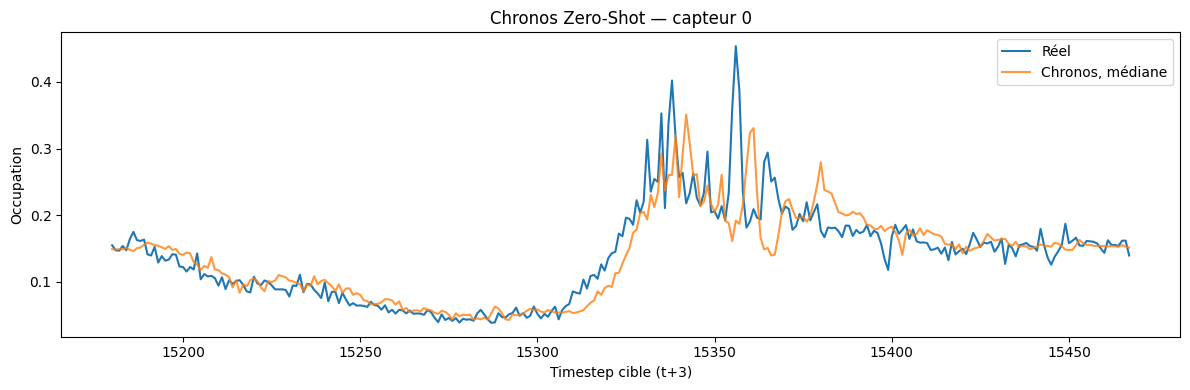

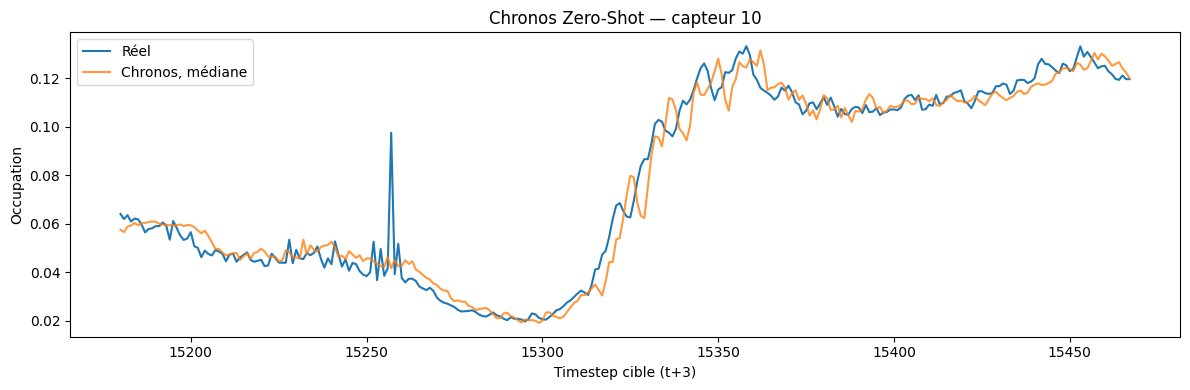

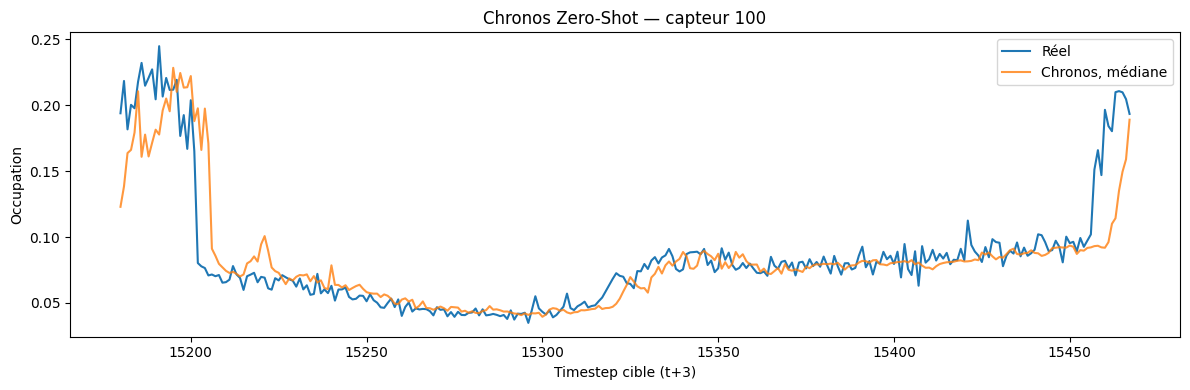

In [8]:
plot_data = test[["location", "timestep"]].copy()
plot_data["actual"] = chronos_actual
plot_data["prediction"] = chronos_predictions
for node in [0, 10, 100]:
    # Afficher un échantillon temporel indépendant par capteur.
    extrait = plot_data.loc[plot_data.location.eq(node)].sort_values("timestep").head(288)
    plt.figure(figsize=(12, 4))
    plt.plot(extrait.timestep + 3, extrait.actual, label="Réel")
    plt.plot(extrait.timestep + 3, extrait.prediction, label="Chronos, médiane", alpha=0.8)
    plt.xlabel("Timestep cible (t+3)")
    plt.ylabel("Occupation")
    plt.title(f"Chronos Zero-Shot — capteur {node}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(dossier_resultats / f"chronos_actual_vs_predicted_sensor_{node}.png", dpi=150, bbox_inches="tight")
    plt.show()

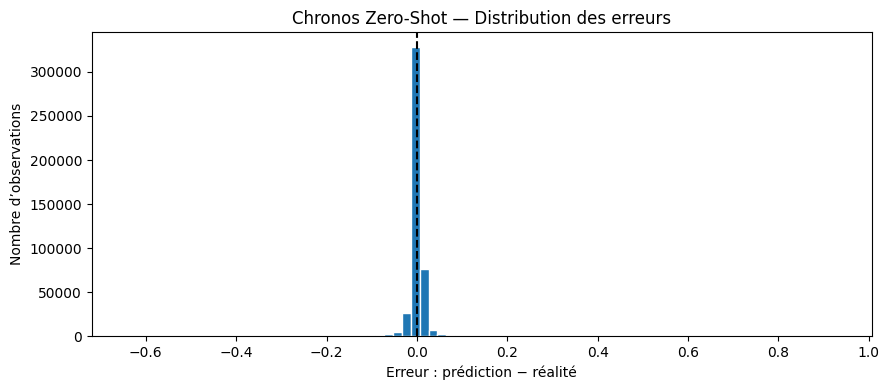

In [9]:
# Décrire les erreurs de toutes les observations test, sans nouvelle inférence.
plt.figure(figsize=(9, 4))
plt.hist(chronos_predictions - chronos_actual, bins=80, edgecolor="white")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Erreur : prédiction − réalité")
plt.ylabel("Nombre d’observations")
plt.title("Chronos Zero-Shot — Distribution des erreurs")
plt.tight_layout()
plt.savefig(dossier_resultats / "chronos_error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

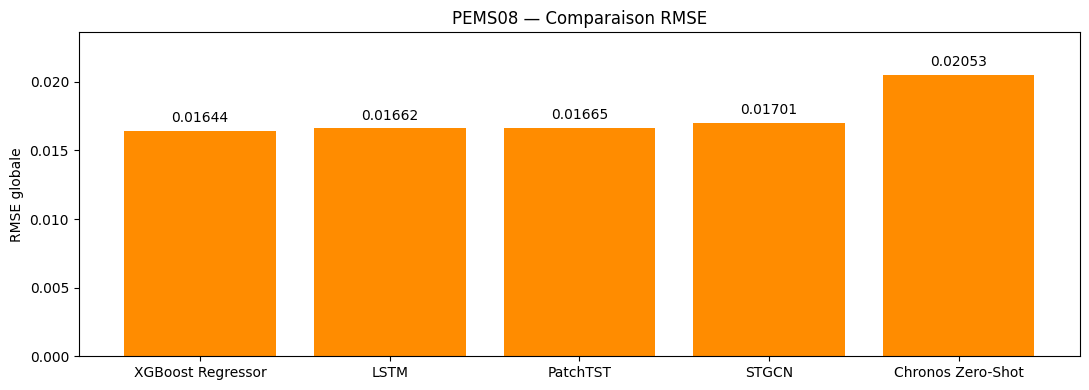

In [10]:
# Comparer les RMSE globales des cinq modèles.
fig, ax = plt.subplots(figsize=(11, 4))
barres = ax.bar(comparaison.model, comparaison.RMSE, color="darkorange")
ax.bar_label(barres, fmt="%.5f", padding=4)
ax.set_ylabel("RMSE globale")
ax.set_title("PEMS08 — Comparaison RMSE")
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig(dossier_resultats / "chronos_models_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

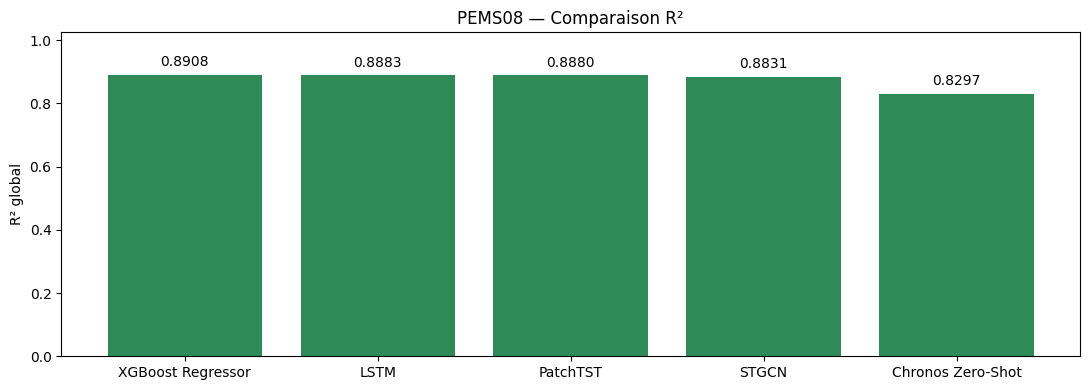

In [11]:
# Comparer les R² globaux sur un graphique séparé.
fig, ax = plt.subplots(figsize=(11, 4))
barres = ax.bar(comparaison.model, comparaison.R2, color="seagreen")
ax.bar_label(barres, fmt="%.4f", padding=4)
ax.axhline(0, color="black", linewidth=0.7)
ax.set_ylabel("R² global")
ax.set_title("PEMS08 — Comparaison R²")
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig(dossier_resultats / "chronos_models_r2.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Analyse automatique et limites

Les conclusions sont calculées à partir des scores réellement obtenus, sans nouvel ajustement après test. Les avantages recherchés sont le transfert de connaissances, l’absence de fit local et la sortie probabiliste native. Les limites comprennent le décalage de domaine, la taille du contexte, l’absence de variables exogènes et de graphe, le coût d’inférence, ainsi que l’absence d’audit complet du corpus de préentraînement. Les différences d’entrée et la convention avant t empêchent d’attribuer le classement au seul effet de l’architecture.

In [12]:
rank_chronos = int(chronos_summary.loc[chronos_summary.Model.eq("Chronos Zero-Shot"), "Rank"].iloc[0])
winner_rmse = comparaison.loc[comparaison.RMSE.idxmin()]
winner_r2 = comparaison.loc[comparaison.R2.idxmax()]
interpretation = (
    f"**Chronos Zero-Shot : MAE={chronos_mae:.6f}, RMSE={chronos_rmse:.6f}, R²={chronos_r2:.4f}**, "
    f"rang RMSE {rank_chronos}/5 sur {len(test):,} observations test.\n\n"
    f"Meilleur selon RMSE : **{winner_rmse['model']}** ({winner_rmse['RMSE']:.6f}). "
    f"Meilleur selon R² : **{winner_r2['model']}** ({winner_r2['R2']:.4f}).\n\n"
    f"L’inférence Chronos a pris {chronos_inference_time_s:.3f} s, soit "
    f"{chronos_inference_time_s / len(test) * 1e6:.3f} µs par ligne en lots. "
    "Le temps d’entraînement local est 0 s ; téléchargement, chargement et préentraînement externe sont exclus.\n\n"
    "Chronos est univarié, zero-shot local, avec contexte t−48..t−1. "
    "Les modèles précédents exploitent d’autres informations, dont la mesure courante t. "
    "Aucun contexte ni quantile n’a été choisi sur test ; aucun avantage d’un foundation model n’est présupposé. "
    "L’absence de PEMS08 dans son corpus de préentraînement n’est pas certifiée par cet audit."
)
display(Markdown(interpretation))
(dossier_resultats / "chronos_methodology.md").write_text(
    "# Chronos Zero-Shot — méthode et résultats\n\n"
    + f"Modèle : {chronos_model_id}, révision {setup['model_revision']}, {chronos_parameter_count} paramètres, {chronos_device}.\n\n"
    + "Source : https://huggingface.co/amazon/chronos-bolt-tiny ; package chronos-forecasting 2.3.2 installé uniquement dans .venv-chronos.\n\n"
    + "Split : cellules temporelles du notebook 02 réutilisées ; clés test identiques aux benchmarks. Aucun entraînement/fine-tuning, aucun fit de scaler global.\n\n"
    + "Contexte : 48 mesures exclusivement avant t ; 4 pas depuis t−1 pour atteindre t+3. Médiane q=0.5, normalisation intégrée sur historique causal et retour dans l’échelle originale.\n\n"
    + interpretation + "\n", encoding="utf-8")

**Chronos Zero-Shot : MAE=0.009108, RMSE=0.020526, R²=0.8297**, rang RMSE 5/5 sur 455,090 observations test.

Meilleur selon RMSE : **XGBoost Regressor** (0.016440). Meilleur selon R² : **XGBoost Regressor** (0.8908).

L’inférence Chronos a pris 166.993 s, soit 366.945 µs par ligne en lots. Le temps d’entraînement local est 0 s ; téléchargement, chargement et préentraînement externe sont exclus.

Chronos est univarié, zero-shot local, avec contexte t−48..t−1. Les modèles précédents exploitent d’autres informations, dont la mesure courante t. Aucun contexte ni quantile n’a été choisi sur test ; aucun avantage d’un foundation model n’est présupposé. L’absence de PEMS08 dans son corpus de préentraînement n’est pas certifiée par cet audit.

1372